# 02 — Tiền xử lý, temporal split và cold-start Diginetica

Notebook này biến dữ liệu raw thành **một bộ dữ liệu dùng chung** cho GRU4Rec, NARM và SASRec. File raw chỉ được đọc, không bị sửa.

## Giao thức đã chốt

- Sắp event trong session theo `timeframe → row_order`.
- Giữ click lặp và session đi qua nửa đêm.
- Loại session không tạo được next-item target.
- Temporal split theo ngày event cuối: 7 ngày cuối là test, 7 ngày trước đó là validation.
- Lọc train bằng fixed-point với `min_session_length=2`, `min_item_frequency=5`.
- Option B giả định: chọn **20% item của catalog train đã lọc**, phân tầng theo category, seed 2024; xóa chúng khỏi train nhưng giữ trong mapping để minh họa embedding chưa huấn luyện.
- Natural cold được ghi riêng, không tính vào tỷ lệ controlled cold 20%.
- Main evaluation chỉ dùng warm item; cold chỉ dùng minh họa theo mô tả đề tài.
- Popularity và rare/medium/popular chỉ được tính từ final train.

> Tài liệu được cung cấp không chứa nội dung Mục 1.6. Vì vậy cold protocol trên là một giả định triển khai minh bạch và phải được thay thế nếu nhận được quy định Option B chính thức.

## 1. Môi trường, cấu hình và đường dẫn

In [1]:
from pathlib import Path
from datetime import timedelta
import hashlib
import json
import sys
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import yaml

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda value: f"{value:,.4f}")
sns.set_theme(style="whitegrid", context="notebook")


def find_project_root(start: Path | None = None) -> Path:
    current = (start or Path.cwd()).resolve()
    for candidate in (current, *current.parents):
        if (candidate / "BTL-K03-tong-quan-de-tai.md").exists():
            return candidate
    raise FileNotFoundError("Không tìm thấy thư mục gốc dự án.")


PROJECT_ROOT = find_project_root()
CONFIG_PATH = PROJECT_ROOT / "configs" / "data.yaml"
with CONFIG_PATH.open("r", encoding="utf-8") as stream:
    CONFIG = yaml.safe_load(stream)

RAW_DIR = PROJECT_ROOT / CONFIG["raw_dir"]
INTERIM_DIR = PROJECT_ROOT / CONFIG["interim_dir"]
PROCESSED_DIR = PROJECT_ROOT / CONFIG["processed_dir"]
RECBOLE_DIR = PROJECT_ROOT / CONFIG["recbole_dir"]
TABLE_DIR = PROJECT_ROOT / "results" / "tables"
FIGURE_DIR = PROJECT_ROOT / "results" / "figures"

for directory in [INTERIM_DIR, PROCESSED_DIR, RECBOLE_DIR, TABLE_DIR, FIGURE_DIR]:
    directory.mkdir(parents=True, exist_ok=True)

MIN_SESSION_LENGTH = int(CONFIG["filtering"]["min_session_length"])
MIN_ITEM_FREQUENCY = int(CONFIG["filtering"]["min_item_frequency"])
VALIDATION_DAYS = int(CONFIG["temporal_split"]["validation_days"])
TEST_DAYS = int(CONFIG["temporal_split"]["test_days"])
COLD_RATIO = float(CONFIG["cold_start"]["ratio"])
COLD_SEED = int(CONFIG["cold_start"]["seed"])
MIN_CATEGORY_ITEMS_FOR_COLD = int(
    CONFIG["cold_start"]["min_pre_holdout_items_per_category"]
)

print("Python       :", sys.executable)
print("Project root :", PROJECT_ROOT)
print("Config       :", CONFIG_PATH)
print("Processed    :", PROCESSED_DIR)
print("Cold protocol:", CONFIG["cold_start"]["protocol"])

Python       : D:\DL\.venv\Scripts\python.exe
Project root : D:\DA-3
Config       : D:\DA-3\configs\data.yaml
Processed    : D:\DA-3\data\processed\diginetica
Cold protocol: controlled_item_holdout_option_b_assumption


## 2. Đọc raw, kiểm tra phiên bản và chuẩn hóa schema

In [2]:
RAW_FILES = {
    "views": RAW_DIR / "train-item-views.csv",
    "categories": RAW_DIR / "product-categories.csv",
    "products": RAW_DIR / "products.csv",
}


def sha256_file(path: Path, chunk_size: int = 1024 * 1024) -> str:
    digest = hashlib.sha256()
    with path.open("rb") as stream:
        for chunk in iter(lambda: stream.read(chunk_size), b""):
            digest.update(chunk)
    return digest.hexdigest()


missing = [str(path) for path in RAW_FILES.values() if not path.exists()]
if missing:
    raise FileNotFoundError(f"Thiếu raw file: {missing}")

views = pd.read_csv(RAW_FILES["views"], sep=";", na_values=["NA"])
categories = pd.read_csv(RAW_FILES["categories"], sep=";")
products = pd.read_csv(RAW_FILES["products"], sep=";")

views = views.rename(columns={
    "sessionId": "session_id",
    "userId": "user_id",
    "itemId": "item_id",
    "eventdate": "event_date",
})
categories = categories.rename(columns={"itemId": "item_id", "categoryId": "category_id"})
products = products.rename(columns={"itemId": "item_id", "product.name.tokens": "product_name_tokens"})

raw_manifest = pd.DataFrame([
    {
        "logical_name": name,
        "file_name": path.name,
        "size_bytes": path.stat().st_size,
        "rows": len({"views": views, "categories": categories, "products": products}[name]),
        "sha256": sha256_file(path),
    }
    for name, path in RAW_FILES.items()
])

eda_manifest_path = TABLE_DIR / "eda_raw_file_manifest.csv"
if eda_manifest_path.exists():
    eda_manifest = pd.read_csv(eda_manifest_path)
    hash_comparison = raw_manifest.merge(
        eda_manifest[["file_name", "sha256"]],
        on="file_name",
        suffixes=("_now", "_eda"),
    )
    if not hash_comparison["sha256_now"].eq(hash_comparison["sha256_eda"]).all():
        raise RuntimeError("Raw file đã thay đổi so với lần chạy EDA.")

if views["item_id"].isna().any() or views["session_id"].isna().any():
    raise ValueError("Raw interaction có missing session_id hoặc item_id.")
if categories["item_id"].duplicated().any():
    raise ValueError("Category mapping có item_id trùng.")
if products["item_id"].duplicated().any():
    raise ValueError("Product table có item_id trùng.")

raw_manifest.to_csv(TABLE_DIR / "preprocessing_raw_manifest.csv", index=False)
display(raw_manifest)

,logical_name,file_name,size_bytes,rows,sha256
0,views,train-item-views.csv,43899457,1235380,5a27dbd1a7d47867ef64aff378dbed971131f0f6fcd86f...
1,categories,product-categories.csv,2163623,184047,e5b7d2cda115f0ec3f5d5d571d247147a23a5ec1bf6249...
2,products,products.csv,7520465,184047,cfe9d17ebd07dba16879a04fc556f223f758001f99a2e3...


## 3. Chuẩn hóa event và tạo bảng session cơ sở

In [3]:
events = views.copy()
events["row_order"] = np.arange(len(events), dtype=np.int64)
events["event_date"] = pd.to_datetime(events["event_date"], errors="raise")
events["timeframe"] = events["timeframe"].astype(np.int64)
events = events.merge(categories, on="item_id", how="left", validate="many_to_one")

if events["category_id"].isna().any():
    raise ValueError("Có interaction thiếu category sau khi join.")

events = events.sort_values(
    ["session_id", "timeframe", "row_order"], kind="mergesort"
).reset_index(drop=True)
events["event_position"] = events.groupby("session_id").cumcount()

session_base = events.groupby("session_id", sort=False).agg(
    session_length=("item_id", "size"),
    unique_items=("item_id", "nunique"),
    first_event_date=("event_date", "min"),
    last_event_date=("event_date", "max"),
    first_timeframe=("timeframe", "min"),
    last_timeframe=("timeframe", "max"),
).reset_index()
session_base["duration_seconds"] = (
    session_base["last_timeframe"] - session_base["first_timeframe"]
) / 1000
session_base["crosses_midnight"] = (
    session_base["first_event_date"] != session_base["last_event_date"]
)

valid_session_ids = pd.Index(
    session_base.loc[
        session_base["session_length"] >= MIN_SESSION_LENGTH, "session_id"
    ]
)
base_events = events[events["session_id"].isin(valid_session_ids)].copy()
base_sessions = session_base[session_base["session_id"].isin(valid_session_ids)].copy()

base_events.to_parquet(
    INTERIM_DIR / "canonical_events.parquet", index=False,
    compression=CONFIG["exports"]["parquet_compression"],
)
base_sessions.to_parquet(
    INTERIM_DIR / "canonical_sessions.parquet", index=False,
    compression=CONFIG["exports"]["parquet_compression"],
)

print(f"Raw events                   : {len(events):,}")
print(f"Events sau session length >=2: {len(base_events):,}")
print(f"Session giữ lại              : {base_events['session_id'].nunique():,}")
print(f"Session qua nửa đêm          : {base_sessions['crosses_midnight'].sum():,}")

Raw events                   : 1,235,380
Events sau session length >=2: 1,144,686
Session giữ lại              : 219,630
Session qua nửa đêm          : 260


## 4. Temporal split theo ngày kết thúc session

In [4]:
DATA_END_DATE = pd.Timestamp(base_sessions["last_event_date"].max())
TEST_START_DATE = DATA_END_DATE - timedelta(days=int(TEST_DAYS) - 1)
VALIDATION_START_DATE = TEST_START_DATE - timedelta(days=int(VALIDATION_DAYS))

base_sessions["split"] = "train"
base_sessions.loc[
    base_sessions["last_event_date"] >= VALIDATION_START_DATE, "split"
] = "validation"
base_sessions.loc[
    base_sessions["last_event_date"] >= TEST_START_DATE, "split"
] = "test"

base_events = base_events.merge(
    base_sessions[["session_id", "last_event_date", "split"]],
    on="session_id", how="left", validate="many_to_one",
)

split_sets = {
    split: set(base_sessions.loc[base_sessions["split"] == split, "session_id"])
    for split in ["train", "validation", "test"]
}
assert split_sets["train"].isdisjoint(split_sets["validation"])
assert split_sets["train"].isdisjoint(split_sets["test"])
assert split_sets["validation"].isdisjoint(split_sets["test"])

base_split_stats = base_events.groupby("split").agg(
    events=("item_id", "size"),
    sessions=("session_id", "nunique"),
    items=("item_id", "nunique"),
    first_date=("last_event_date", "min"),
    last_date=("last_event_date", "max"),
).reindex(["train", "validation", "test"]).reset_index()

print("Data end       :", DATA_END_DATE.date())
print("Validation from:", VALIDATION_START_DATE.date())
print("Test from      :", TEST_START_DATE.date())
display(base_split_stats)

Data end       : 2016-06-01
Validation from: 2016-05-19
Test from      : 2016-05-26


,split,events,sessions,items,first_date,last_date
0,train,990708,189774,114768,2016-01-01,2016-05-18
1,validation,65533,12701,25611,2016-05-19,2016-05-25
2,test,88445,17155,30290,2016-05-26,2016-06-01


## 5. Lọc fixed-point trên train trước khi tạo controlled cold

In [5]:
def stage_stats(stage: str, frame: pd.DataFrame) -> dict:
    return {
        "stage": stage,
        "events": int(len(frame)),
        "sessions": int(frame["session_id"].nunique()),
        "items": int(frame["item_id"].nunique()),
        "categories": int(frame["category_id"].nunique()),
        "prefix_target_examples": int(
            (frame.groupby("session_id").size() - 1).clip(lower=0).sum()
        ),
    }


def fixed_point_filter(
    frame: pd.DataFrame,
    min_session_length: int,
    min_item_frequency: int,
    stage_prefix: str,
    max_iterations: int = 100,
) -> tuple[pd.DataFrame, pd.DataFrame]:
    filtered = frame.copy()
    history = [stage_stats(f"{stage_prefix}_input", filtered)]

    for iteration in range(1, max_iterations + 1):
        before = (
            len(filtered),
            filtered["session_id"].nunique(),
            filtered["item_id"].nunique(),
        )

        session_sizes = filtered.groupby("session_id").size()
        filtered = filtered[
            filtered["session_id"].isin(
                session_sizes[session_sizes >= min_session_length].index
            )
        ].copy()

        item_frequency = filtered["item_id"].value_counts()
        filtered = filtered[
            filtered["item_id"].isin(
                item_frequency[item_frequency >= min_item_frequency].index
            )
        ].copy()

        filtered = filtered.sort_values(
            ["session_id", "timeframe", "row_order"], kind="mergesort"
        )
        history.append(stage_stats(f"{stage_prefix}_iteration_{iteration}", filtered))

        after = (
            len(filtered),
            filtered["session_id"].nunique(),
            filtered["item_id"].nunique(),
        )
        if after == before:
            return filtered.reset_index(drop=True), pd.DataFrame(history)

    raise RuntimeError("Fixed-point filtering không hội tụ.")


raw_train = base_events[base_events["split"] == "train"].copy()
raw_validation = base_events[base_events["split"] == "validation"].copy()
raw_test = base_events[base_events["split"] == "test"].copy()

train_pre_cold, pre_cold_history = fixed_point_filter(
    raw_train,
    min_session_length=MIN_SESSION_LENGTH,
    min_item_frequency=MIN_ITEM_FREQUENCY,
    stage_prefix="pre_cold_train",
)

pre_cold_frequency = train_pre_cold["item_id"].value_counts().rename(
    "pre_holdout_train_frequency"
)
print("Train trước cold holdout:")
display(pre_cold_history)

Train trước cold holdout:


,stage,events,sessions,items,categories,prefix_target_examples
0,pre_cold_train_input,990708,189774,114768,1192,800934
1,pre_cold_train_iteration_1,856503,186264,39204,977,670239
2,pre_cold_train_iteration_2,842325,175337,38309,949,666988
3,pre_cold_train_iteration_3,841486,174747,38244,948,666739
4,pre_cold_train_iteration_4,841406,174695,38237,948,666711
5,pre_cold_train_iteration_5,841402,174691,38237,948,666711
6,pre_cold_train_iteration_6,841402,174691,38237,948,666711


## 6. Tạo controlled cold 20% theo category

Tỷ lệ 20% tính trên catalog train đã qua lọc trước cold. Category phải có ít nhất 5 item trước holdout; quota theo category được phân bổ theo phương pháp largest remainder và luôn chừa ít nhất một warm item. Natural cold do temporal split được ghi riêng.

In [6]:
def select_category_stratified_cold_items(
    item_category: pd.DataFrame,
    ratio: float,
    seed: int,
    min_category_items: int,
) -> tuple[pd.DataFrame, pd.DataFrame]:
    catalog = item_category.drop_duplicates("item_id").copy()
    category_sizes = catalog.groupby("category_id").size().rename("category_items").reset_index()
    category_sizes["eligible_category"] = category_sizes["category_items"] >= min_category_items
    category_sizes["capacity"] = np.where(
        category_sizes["eligible_category"],
        category_sizes["category_items"] - 1,
        0,
    ).astype(int)
    category_sizes["ideal_quota"] = ratio * category_sizes["category_items"]
    category_sizes["quota"] = np.minimum(
        np.floor(category_sizes["ideal_quota"]).astype(int),
        category_sizes["capacity"],
    )
    category_sizes["fractional_remainder"] = (
        category_sizes["ideal_quota"] - np.floor(category_sizes["ideal_quota"])
    )

    target = int(round(ratio * len(catalog)))
    if category_sizes["capacity"].sum() < target:
        raise ValueError("Không đủ item hợp lệ để tạo đúng cold ratio.")

    rng = np.random.default_rng(seed)
    category_sizes["tie_break"] = rng.random(len(category_sizes))
    remaining = target - int(category_sizes["quota"].sum())

    while remaining > 0:
        candidates = category_sizes[
            category_sizes["quota"] < category_sizes["capacity"]
        ].sort_values(
            ["fractional_remainder", "tie_break"], ascending=[False, True]
        )
        if candidates.empty:
            raise RuntimeError("Không thể phân bổ đủ cold quota.")
        take_indices = candidates.index[:remaining]
        category_sizes.loc[take_indices, "quota"] += 1
        remaining -= len(take_indices)

    selected_parts = []
    quota_map = category_sizes.set_index("category_id")["quota"]
    for category_id, group in catalog.groupby("category_id", sort=True):
        quota = int(quota_map.loc[category_id])
        if quota == 0:
            continue
        item_ids = np.sort(group["item_id"].to_numpy())
        chosen = rng.choice(item_ids, size=quota, replace=False)
        selected_parts.append(pd.DataFrame({
            "item_id": chosen,
            "category_id": category_id,
        }))

    selected = pd.concat(selected_parts, ignore_index=True)
    if len(selected) != target:
        raise AssertionError("Số controlled cold item không bằng target.")
    return selected.sort_values("item_id").reset_index(drop=True), category_sizes


pre_cold_item_category = train_pre_cold[["item_id", "category_id"]].drop_duplicates()
controlled_cold, cold_allocation = select_category_stratified_cold_items(
    pre_cold_item_category,
    ratio=COLD_RATIO,
    seed=COLD_SEED,
    min_category_items=MIN_CATEGORY_ITEMS_FOR_COLD,
)
controlled_cold_ids = pd.Index(controlled_cold["item_id"])

raw_train_items = pd.Index(raw_train["item_id"].unique())
future_items = pd.Index(
    pd.concat([raw_validation["item_id"], raw_test["item_id"]]).unique()
)
natural_cold_ids = future_items.difference(raw_train_items)

future_frequency = pd.concat([
    raw_validation["item_id"], raw_test["item_id"]
]).value_counts().rename("future_frequency")
controlled_cold = controlled_cold.merge(
    pre_cold_frequency, left_on="item_id", right_index=True, how="left"
).merge(
    future_frequency, left_on="item_id", right_index=True, how="left"
)
controlled_cold["future_frequency"] = controlled_cold["future_frequency"].fillna(0).astype(int)
controlled_cold["cold_type"] = "controlled_option_b"
controlled_cold["selection_seed"] = COLD_SEED

cold_allocation.to_csv(TABLE_DIR / "cold_category_allocation.csv", index=False)
print(f"Catalog train trước holdout: {len(pre_cold_item_category):,} item")
print(f"Controlled cold 20%        : {len(controlled_cold):,} item")
print(f"Tỷ lệ thực tế              : {len(controlled_cold) / len(pre_cold_item_category) * 100:.4f}%")
print(f"Natural cold do thời gian  : {len(natural_cold_ids):,} item")
print(f"Controlled cold có future event: {controlled_cold['future_frequency'].gt(0).sum():,}")

Catalog train trước holdout: 38,237 item


Controlled cold 20%        : 7,647 item
Tỷ lệ thực tế              : 19.9990%
Natural cold do thời gian  : 6,700 item
Controlled cold có future event: 4,630


## 7. Loại controlled cold khỏi train và tạo warm evaluation splits

In [7]:
train_after_cold_removal = train_pre_cold[
    ~train_pre_cold["item_id"].isin(controlled_cold_ids)
].copy()

train_final, post_cold_history = fixed_point_filter(
    train_after_cold_removal,
    min_session_length=MIN_SESSION_LENGTH,
    min_item_frequency=MIN_ITEM_FREQUENCY,
    stage_prefix="post_cold_train",
)
warm_item_ids = pd.Index(train_final["item_id"].unique())


def keep_warm_evaluation_events(frame: pd.DataFrame, warm_ids: pd.Index) -> pd.DataFrame:
    filtered = frame[frame["item_id"].isin(warm_ids)].copy()
    session_sizes = filtered.groupby("session_id").size()
    filtered = filtered[
        filtered["session_id"].isin(
            session_sizes[session_sizes >= MIN_SESSION_LENGTH].index
        )
    ].copy()
    return filtered.sort_values(
        ["session_id", "timeframe", "row_order"], kind="mergesort"
    ).reset_index(drop=True)


validation_final = keep_warm_evaluation_events(raw_validation, warm_item_ids)
test_final = keep_warm_evaluation_events(raw_test, warm_item_ids)

post_holdout_attrition_ids = (
    pd.Index(pre_cold_item_category["item_id"])
    .difference(controlled_cold_ids)
    .difference(warm_item_ids)
)

attrition = pd.concat([
    pre_cold_history,
    pd.DataFrame([stage_stats("after_controlled_cold_removal", train_after_cold_removal)]),
    post_cold_history,
], ignore_index=True)
attrition["events_retained_vs_raw_train_pct"] = attrition["events"] / len(raw_train) * 100
attrition["items_retained_vs_raw_train_pct"] = (
    attrition["items"] / raw_train["item_id"].nunique() * 100
)

print("Train sau controlled cold và fixed-point:")
display(post_cold_history)
print(f"Final warm items             : {len(warm_item_ids):,}")
print(f"Post-holdout attrition items : {len(post_holdout_attrition_ids):,}")

Train sau controlled cold và fixed-point:


,stage,events,sessions,items,categories,prefix_target_examples
0,post_cold_train_input,671642,170305,30590,948,501337
1,post_cold_train_iteration_1,650293,151259,29985,945,499034
2,post_cold_train_iteration_2,649704,150827,29944,945,498877
3,post_cold_train_iteration_3,649652,150794,29939,945,498858
4,post_cold_train_iteration_4,649638,150786,29937,945,498852
5,post_cold_train_iteration_5,649633,150784,29936,945,498849
6,post_cold_train_iteration_6,649632,150783,29936,945,498849
7,post_cold_train_iteration_7,649632,150783,29936,945,498849


Final warm items             : 29,936
Post-holdout attrition items : 654


## 8. Item mapping và nhóm popularity từ final train

In [8]:
final_train_frequency = train_final["item_id"].value_counts().rename("train_frequency")
rare_quantile = float(CONFIG["popularity_groups"]["rare_quantile"])
popular_quantile = float(CONFIG["popularity_groups"]["popular_quantile"])
rare_threshold = int(final_train_frequency.quantile(rare_quantile, interpolation="higher"))
popular_threshold = int(final_train_frequency.quantile(popular_quantile, interpolation="lower"))


def popularity_group(frequency: int) -> str:
    if frequency <= rare_threshold:
        return "rare"
    if frequency >= popular_threshold:
        return "popular"
    return "medium"


model_catalog_ids = warm_item_ids.union(controlled_cold_ids).sort_values()
item_mapping = pd.DataFrame({"item_id": model_catalog_ids})
item_mapping.insert(
    0,
    "internal_item_id",
    np.arange(1, len(item_mapping) + 1, dtype=np.int64),
)
item_mapping = item_mapping.merge(categories, on="item_id", how="left", validate="one_to_one")
item_mapping = item_mapping.merge(
    pre_cold_frequency, left_on="item_id", right_index=True, how="left"
).merge(
    final_train_frequency, left_on="item_id", right_index=True, how="left"
).merge(
    future_frequency, left_on="item_id", right_index=True, how="left"
)
for column in ["pre_holdout_train_frequency", "train_frequency", "future_frequency"]:
    item_mapping[column] = item_mapping[column].fillna(0).astype(int)

item_mapping["is_controlled_cold"] = item_mapping["item_id"].isin(controlled_cold_ids)
item_mapping["is_trainable_warm"] = item_mapping["item_id"].isin(warm_item_ids)
item_mapping["popularity_group"] = item_mapping["train_frequency"].map(
    lambda value: "cold" if value == 0 else popularity_group(int(value))
)
item_mapping["candidate_for_main_evaluation"] = item_mapping["is_trainable_warm"]

category_mapping = pd.DataFrame({
    "category_id": np.sort(item_mapping["category_id"].unique())
})
category_mapping.insert(
    0,
    "internal_category_id",
    np.arange(1, len(category_mapping) + 1, dtype=np.int64),
)
item_mapping = item_mapping.merge(
    category_mapping, on="category_id", how="left", validate="many_to_one"
)

natural_cold = categories[
    categories["item_id"].isin(natural_cold_ids)
].copy()
natural_cold["cold_type"] = "natural_temporal"
natural_cold["selection_seed"] = pd.NA
natural_cold["pre_holdout_train_frequency"] = 0
natural_cold["train_frequency"] = 0
natural_cold = natural_cold.merge(
    future_frequency, left_on="item_id", right_index=True, how="left"
)
natural_cold["future_frequency"] = natural_cold["future_frequency"].fillna(0).astype(int)
natural_cold["internal_item_id"] = pd.NA
natural_cold["in_model_catalog"] = False

controlled_cold_export = item_mapping[
    item_mapping["is_controlled_cold"]
][[
    "item_id", "internal_item_id", "category_id",
    "pre_holdout_train_frequency", "train_frequency", "future_frequency",
]].copy()
controlled_cold_export["cold_type"] = "controlled_option_b"
controlled_cold_export["selection_seed"] = COLD_SEED
controlled_cold_export["in_model_catalog"] = True

cold_items = pd.concat([
    controlled_cold_export,
    natural_cold[controlled_cold_export.columns],
], ignore_index=True)

popularity_summary = item_mapping.groupby("popularity_group").agg(
    items=("item_id", "size"),
    train_interactions=("train_frequency", "sum"),
    min_train_frequency=("train_frequency", "min"),
    median_train_frequency=("train_frequency", "median"),
    max_train_frequency=("train_frequency", "max"),
).reset_index()
popularity_summary["item_share_pct"] = popularity_summary["items"] / len(item_mapping) * 100

print(f"Rare threshold    : frequency <= {rare_threshold}")
print(f"Popular threshold : frequency >= {popular_threshold}")
display(popularity_summary)

Rare threshold    : frequency <= 6
Popular threshold : frequency >= 27


,popularity_group,items,train_interactions,min_train_frequency,median_train_frequency,max_train_frequency,item_share_pct
0,cold,7647,0,0,0.0000,0,20.3470
1,medium,16940,218091,7,11.0000,26,45.0736
2,popular,6112,394016,27,45.0000,860,16.2627
3,rare,6884,37525,5,5.0000,6,18.3168


## 9. Ánh xạ event, tạo session sequence và prefix-target examples

In [9]:
item_to_internal = item_mapping.set_index("item_id")["internal_item_id"]
item_to_group = item_mapping.set_index("item_id")["popularity_group"]


def map_events(frame: pd.DataFrame, allow_missing_internal: bool = False) -> pd.DataFrame:
    mapped = frame.copy()
    mapped["internal_item_id"] = mapped["item_id"].map(item_to_internal)
    mapped["popularity_group"] = mapped["item_id"].map(item_to_group)
    mapped["is_controlled_cold"] = mapped["item_id"].isin(controlled_cold_ids)
    mapped["is_natural_cold"] = mapped["item_id"].isin(natural_cold_ids)
    if not allow_missing_internal and mapped["internal_item_id"].isna().any():
        raise ValueError("Main split có item không nằm trong model mapping.")
    if not allow_missing_internal:
        mapped["internal_item_id"] = mapped["internal_item_id"].astype(np.int64)
    else:
        mapped["internal_item_id"] = mapped["internal_item_id"].astype("Int64")
    mapped["sequence_position"] = mapped.groupby("session_id").cumcount()
    return mapped


train_mapped = map_events(train_final)
validation_mapped = map_events(validation_final)
test_mapped = map_events(test_final)
validation_full_mapped = map_events(raw_validation, allow_missing_internal=True)
test_full_mapped = map_events(raw_test, allow_missing_internal=True)


def make_session_sequences(frame: pd.DataFrame, split: str) -> pd.DataFrame:
    rows = []
    for session_id, group in frame.groupby("session_id", sort=False):
        rows.append({
            "session_id": int(session_id),
            "split": split,
            "session_end_date": group["last_event_date"].max(),
            "item_sequence": group["internal_item_id"].astype(int).tolist(),
            "raw_item_sequence": group["item_id"].astype(int).tolist(),
            "sequence_length": int(len(group)),
        })
    return pd.DataFrame(rows)


def make_examples(session_frame: pd.DataFrame) -> tuple[pd.DataFrame, pd.DataFrame]:
    all_rows = []
    last_rows = []
    group_lookup = item_mapping.set_index("internal_item_id")["popularity_group"]
    raw_lookup = item_mapping.set_index("internal_item_id")["item_id"]

    for row in session_frame.itertuples(index=False):
        sequence = list(row.item_sequence)
        for target_position in range(1, len(sequence)):
            target = int(sequence[target_position])
            all_rows.append({
                "session_id": int(row.session_id),
                "split": row.split,
                "prefix_items": sequence[:target_position],
                "prefix_length": target_position,
                "target_internal_item_id": target,
                "target_item_id": int(raw_lookup.loc[target]),
                "target_popularity_group": group_lookup.loc[target],
            })

        target = int(sequence[-1])
        last_rows.append({
            "session_id": int(row.session_id),
            "split": row.split,
            "prefix_items": sequence[:-1],
            "prefix_length": len(sequence) - 1,
            "target_internal_item_id": target,
            "target_item_id": int(raw_lookup.loc[target]),
            "target_popularity_group": group_lookup.loc[target],
        })

    return pd.DataFrame(all_rows), pd.DataFrame(last_rows)


train_sessions = make_session_sequences(train_mapped, "train")
validation_sessions = make_session_sequences(validation_mapped, "validation")
test_sessions = make_session_sequences(test_mapped, "test")

train_examples, train_last_examples = make_examples(train_sessions)
validation_examples, validation_last_examples = make_examples(validation_sessions)
test_examples, test_last_examples = make_examples(test_sessions)

example_summary = pd.DataFrame([
    {
        "split": split,
        "sessions": len(sessions),
        "all_prefix_examples": len(examples),
        "last_item_examples": len(last_examples),
    }
    for split, sessions, examples, last_examples in [
        ("train", train_sessions, train_examples, train_last_examples),
        ("validation", validation_sessions, validation_examples, validation_last_examples),
        ("test", test_sessions, test_examples, test_last_examples),
    ]
])
display(example_summary)

,split,sessions,all_prefix_examples,last_item_examples
0,train,150783,498849,150783
1,validation,9622,29828,9622
2,test,12791,40001,12791


## 10. Xuất dữ liệu processed và định dạng RecBole

In [10]:
PARQUET_COMPRESSION = CONFIG["exports"]["parquet_compression"]

parquet_outputs = {
    "train_events.parquet": train_mapped,
    "validation_events.parquet": validation_mapped,
    "test_events.parquet": test_mapped,
    "validation_events_full.parquet": validation_full_mapped,
    "test_events_full.parquet": test_full_mapped,
    "train_sessions.parquet": train_sessions,
    "validation_sessions.parquet": validation_sessions,
    "test_sessions.parquet": test_sessions,
    "train_examples.parquet": train_examples,
    "validation_examples.parquet": validation_examples,
    "test_examples.parquet": test_examples,
    "train_last_item_examples.parquet": train_last_examples,
    "validation_last_item_examples.parquet": validation_last_examples,
    "test_last_item_examples.parquet": test_last_examples,
}
for file_name, frame in parquet_outputs.items():
    frame.to_parquet(
        PROCESSED_DIR / file_name,
        index=False,
        compression=PARQUET_COMPRESSION,
    )

item_mapping.to_csv(PROCESSED_DIR / "item_mapping.csv", index=False)
category_mapping.to_csv(PROCESSED_DIR / "category_mapping.csv", index=False)
item_mapping[[
    "item_id", "internal_item_id", "category_id", "train_frequency",
    "popularity_group", "is_controlled_cold", "candidate_for_main_evaluation",
]].to_csv(PROCESSED_DIR / "popularity_groups.csv", index=False)
cold_items.to_csv(PROCESSED_DIR / "cold_items.csv", index=False)


def export_recbole_inter(frame: pd.DataFrame, path: Path) -> None:
    export = frame[["session_id", "internal_item_id", "timeframe"]].copy()
    export.columns = ["session_id:token", "item_id:token", "timestamp:float"]
    export.to_csv(path, sep="\t", index=False)


export_recbole_inter(train_mapped, RECBOLE_DIR / "diginetica.train.inter")
export_recbole_inter(validation_mapped, RECBOLE_DIR / "diginetica.valid.inter")
export_recbole_inter(test_mapped, RECBOLE_DIR / "diginetica.test.inter")

recbole_items = item_mapping[[
    "internal_item_id", "item_id", "internal_category_id", "is_controlled_cold",
]].copy()
recbole_items.columns = [
    "item_id:token", "raw_item_id:token", "category_id:token", "is_cold:token",
]
recbole_items.to_csv(
    RECBOLE_DIR / "diginetica.item", sep="\t", index=False
)

attrition.to_csv(TABLE_DIR / "preprocessing_attrition_official.csv", index=False)
base_split_stats.to_csv(TABLE_DIR / "preprocessing_base_split_statistics.csv", index=False)
example_summary.to_csv(TABLE_DIR / "preprocessing_example_summary.csv", index=False)
popularity_summary.to_csv(TABLE_DIR / "preprocessing_popularity_group_summary.csv", index=False)

with (PROCESSED_DIR / "preprocessing_config.json").open("w", encoding="utf-8") as stream:
    json.dump(CONFIG, stream, ensure_ascii=False, indent=2)

print(f"Đã xuất {len(parquet_outputs)} parquet files vào {PROCESSED_DIR}")
print(f"Đã xuất RecBole atomic files vào {RECBOLE_DIR}")

Đã xuất 14 parquet files vào D:\DA-3\data\processed\diginetica
Đã xuất RecBole atomic files vào D:\DA-3\data\processed\recbole\diginetica


## 11. Audit leakage, cold protocol, mapping và split

In [11]:
def nondecreasing_within_session(frame: pd.DataFrame) -> bool:
    return bool(
        frame.groupby("session_id", sort=False)["timeframe"]
        .diff().fillna(0).ge(0).all()
    )


final_split_sets = {
    "train": set(train_mapped["session_id"]),
    "validation": set(validation_mapped["session_id"]),
    "test": set(test_mapped["session_id"]),
}
controlled_cold_set = set(controlled_cold_ids)
train_item_set = set(train_mapped["item_id"])
warm_item_set = set(warm_item_ids)

cold_categories = set(
    item_mapping.loc[item_mapping["is_controlled_cold"], "category_id"]
)
warm_categories = set(
    item_mapping.loc[item_mapping["is_trainable_warm"], "category_id"]
)

expected_controlled_cold = int(round(COLD_RATIO * len(pre_cold_item_category)))
checks = pd.DataFrame([
    ("raw_hashes_match_eda", True, "Ba SHA-256 khớp manifest EDA"),
    ("train_order_nondecreasing", nondecreasing_within_session(train_mapped), "timeframe không giảm"),
    ("validation_order_nondecreasing", nondecreasing_within_session(validation_mapped), "timeframe không giảm"),
    ("test_order_nondecreasing", nondecreasing_within_session(test_mapped), "timeframe không giảm"),
    ("train_min_session_length", train_mapped.groupby("session_id").size().min() >= 2, "mọi session >=2"),
    ("validation_min_session_length", validation_mapped.groupby("session_id").size().min() >= 2, "mọi session >=2"),
    ("test_min_session_length", test_mapped.groupby("session_id").size().min() >= 2, "mọi session >=2"),
    ("train_validation_sessions_disjoint", final_split_sets["train"].isdisjoint(final_split_sets["validation"]), "không trùng session"),
    ("train_test_sessions_disjoint", final_split_sets["train"].isdisjoint(final_split_sets["test"]), "không trùng session"),
    ("validation_test_sessions_disjoint", final_split_sets["validation"].isdisjoint(final_split_sets["test"]), "không trùng session"),
    ("controlled_cold_count_exact", len(controlled_cold_set) == expected_controlled_cold, f"expected={expected_controlled_cold:,}"),
    ("controlled_cold_absent_from_train", controlled_cold_set.isdisjoint(train_item_set), "cold ∩ train = ∅"),
    ("controlled_cold_has_warm_category_peer", cold_categories.issubset(warm_categories), "mọi cold category còn warm item"),
    ("main_validation_warm_only", set(validation_mapped["item_id"]).issubset(warm_item_set), "validation item ⊆ warm"),
    ("main_test_warm_only", set(test_mapped["item_id"]).issubset(warm_item_set), "test item ⊆ warm"),
    ("mapping_internal_ids_unique", item_mapping["internal_item_id"].is_unique, "internal id duy nhất"),
    ("mapping_raw_ids_unique", item_mapping["item_id"].is_unique, "raw id duy nhất"),
    ("mapping_starts_at_one", item_mapping["internal_item_id"].min() == 1, "0 dành cho padding"),
    ("mapping_categories_complete", item_mapping["category_id"].notna().all(), "không thiếu category"),
    ("train_frequency_minimum", final_train_frequency.min() >= MIN_ITEM_FREQUENCY, f"min >= {MIN_ITEM_FREQUENCY}"),
    ("popularity_from_train_only", item_mapping.loc[item_mapping["is_trainable_warm"], "train_frequency"].sum() == len(train_mapped), "tổng frequency bằng train events"),
    ("train_before_validation", train_mapped["last_event_date"].max() < VALIDATION_START_DATE, "temporal boundary đúng"),
    ("validation_before_test", validation_mapped["last_event_date"].max() < TEST_START_DATE, "temporal boundary đúng"),
])
checks.columns = ["check", "passed", "evidence"]

if not checks["passed"].all():
    display(checks[~checks["passed"]])
    raise AssertionError("Preprocessing audit thất bại.")

checks.to_csv(TABLE_DIR / "preprocessing_checks.csv", index=False)
display(checks)

,check,passed,evidence
0,raw_hashes_match_eda,True,Ba SHA-256 khớp manifest EDA
1,train_order_nondecreasing,True,timeframe không giảm
2,validation_order_nondecreasing,True,timeframe không giảm
3,test_order_nondecreasing,True,timeframe không giảm
4,train_min_session_length,True,mọi session >=2
5,validation_min_session_length,True,mọi session >=2
6,test_min_session_length,True,mọi session >=2
7,train_validation_sessions_disjoint,True,không trùng session
8,train_test_sessions_disjoint,True,không trùng session
9,validation_test_sessions_disjoint,True,không trùng session


## 12. Thống kê cuối và biểu đồ bàn giao

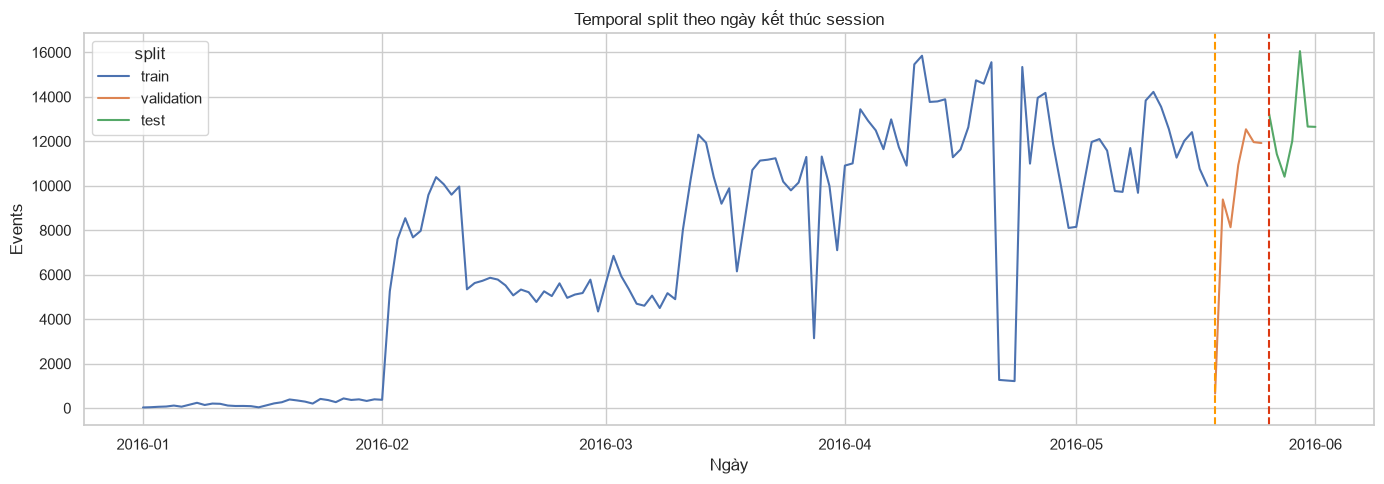

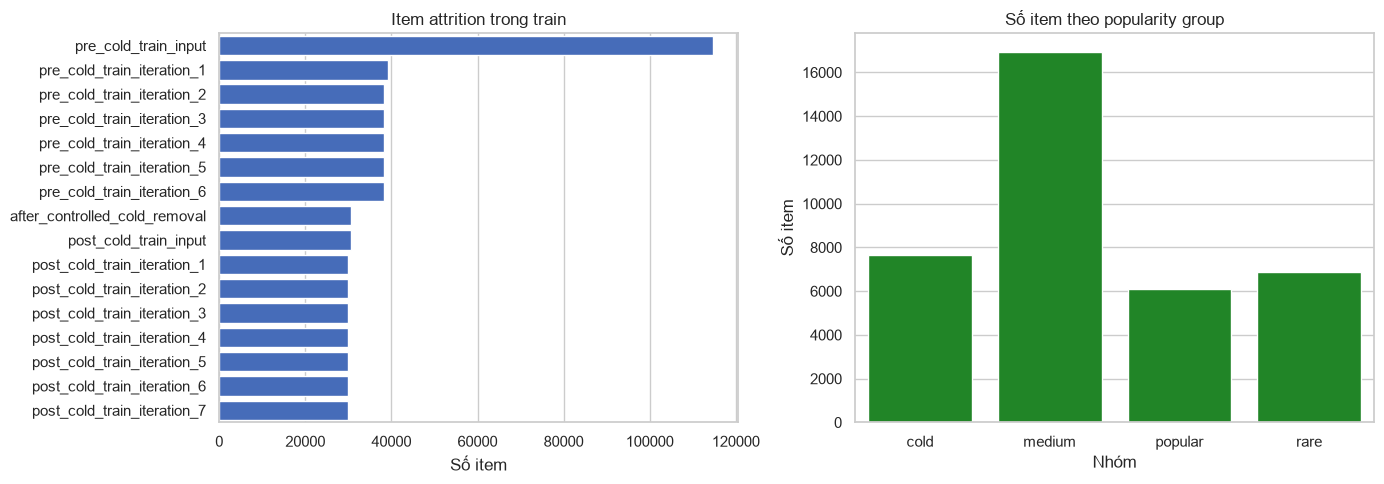

,stage,events,sessions,items,categories,prefix_target_examples
0,train,649632,150783,29936,945,498849
1,validation_warm,39450,9622,12227,704,29828
2,test_warm,52792,12791,13847,738,40001


,metric,value
0,pre_holdout_filtered_train_items,"38,237.0000"
1,controlled_cold_items,"7,647.0000"
2,controlled_cold_ratio_pct,19.9990
3,controlled_cold_with_future_events,"4,630.0000"
4,natural_temporal_cold_items,"6,700.0000"
5,final_warm_items,"29,936.0000"
6,post_holdout_attrition_items,654.0000
7,cold_categories,629.0000
8,cold_categories_with_warm_peer,629.0000


In [12]:
final_split_stats = pd.DataFrame([
    stage_stats("train", train_mapped),
    stage_stats("validation_warm", validation_mapped),
    stage_stats("test_warm", test_mapped),
])
final_split_stats.to_csv(TABLE_DIR / "preprocessing_final_split_statistics.csv", index=False)

cold_start_summary = pd.DataFrame([
    ("pre_holdout_filtered_train_items", len(pre_cold_item_category)),
    ("controlled_cold_items", len(controlled_cold_ids)),
    ("controlled_cold_ratio_pct", len(controlled_cold_ids) / len(pre_cold_item_category) * 100),
    ("controlled_cold_with_future_events", int(controlled_cold["future_frequency"].gt(0).sum())),
    ("natural_temporal_cold_items", len(natural_cold_ids)),
    ("final_warm_items", len(warm_item_ids)),
    ("post_holdout_attrition_items", len(post_holdout_attrition_ids)),
    ("cold_categories", len(cold_categories)),
    ("cold_categories_with_warm_peer", len(cold_categories & warm_categories)),
], columns=["metric", "value"])
cold_start_summary.to_csv(TABLE_DIR / "preprocessing_cold_start_summary.csv", index=False)

dataset_statistics = {
    "dataset": "diginetica",
    "data_end_date": str(DATA_END_DATE.date()),
    "validation_start_date": str(VALIDATION_START_DATE.date()),
    "test_start_date": str(TEST_START_DATE.date()),
    "min_session_length": MIN_SESSION_LENGTH,
    "min_item_frequency": MIN_ITEM_FREQUENCY,
    "controlled_cold_ratio_requested": COLD_RATIO,
    "controlled_cold_ratio_actual": len(controlled_cold_ids) / len(pre_cold_item_category),
    "controlled_cold_seed": COLD_SEED,
    "rare_frequency_max": rare_threshold,
    "popular_frequency_min": popular_threshold,
    "final_splits": final_split_stats.to_dict(orient="records"),
    "examples": example_summary.to_dict(orient="records"),
    "audit_passed": bool(checks["passed"].all()),
}
with (PROCESSED_DIR / "dataset_statistics.json").open("w", encoding="utf-8") as stream:
    json.dump(dataset_statistics, stream, ensure_ascii=False, indent=2)

daily_split = base_events.groupby(["last_event_date", "split"]).size().rename("events").reset_index()
fig, ax = plt.subplots(figsize=(14, 5))
sns.lineplot(data=daily_split, x="last_event_date", y="events", hue="split", ax=ax)
ax.axvline(VALIDATION_START_DATE, color="#ff9900", linestyle="--", label="validation start")
ax.axvline(TEST_START_DATE, color="#dc3912", linestyle="--", label="test start")
ax.set(title="Temporal split theo ngày kết thúc session", xlabel="Ngày", ylabel="Events")
fig.tight_layout()
fig.savefig(FIGURE_DIR / "preprocessing_temporal_split.png", dpi=180, bbox_inches="tight")
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
plot_attrition = attrition.drop_duplicates("stage", keep="last")
sns.barplot(data=plot_attrition, x="items", y="stage", ax=axes[0], color="#3366cc")
axes[0].set(title="Item attrition trong train", xlabel="Số item", ylabel="")

group_plot = popularity_summary.copy()
sns.barplot(data=group_plot, x="popularity_group", y="items", ax=axes[1], color="#109618")
axes[1].set(title="Số item theo popularity group", xlabel="Nhóm", ylabel="Số item")
fig.tight_layout()
fig.savefig(FIGURE_DIR / "preprocessing_attrition_and_groups.png", dpi=180, bbox_inches="tight")
plt.show()

display(final_split_stats)
display(cold_start_summary)

## 13. Kết luận và bàn giao cho ba notebook huấn luyện

In [13]:
print("PREPROCESSING HOÀN TẤT")
print("=" * 60)
print(f"Train/validation/test boundary : < {VALIDATION_START_DATE.date()} / < {TEST_START_DATE.date()} / còn lại")
print(f"Final train events/sessions/items: {len(train_mapped):,} / {train_mapped['session_id'].nunique():,} / {len(warm_item_ids):,}")
print(f"Controlled cold               : {len(controlled_cold_ids):,} ({COLD_RATIO * 100:.0f}% pre-holdout train catalog)")
print(f"Natural temporal cold         : {len(natural_cold_ids):,}")
print(f"Popularity thresholds         : rare <= {rare_threshold}; popular >= {popular_threshold}")
print(f"Audit checks passed           : {checks['passed'].sum()}/{len(checks)}")
print()
print("Lưu ý bắt buộc cho notebook huấn luyện:")
print("1. Dùng đúng item_mapping.csv và cùng split cho cả ba mô hình.")
print("2. Main metrics chỉ dùng candidate_for_main_evaluation=True.")
print("3. Controlled cold không được positive/negative sample và không được nhận gradient.")
print("4. Lưu embedding khởi tạo để xác minh cold embedding chưa huấn luyện.")
print("5. Nếu nhận được Mục 1.6/Option B chính thức, chạy lại notebook theo quy định đó.")

PREPROCESSING HOÀN TẤT
Train/validation/test boundary : < 2016-05-19 / < 2016-05-26 / còn lại
Final train events/sessions/items: 649,632 / 150,783 / 29,936
Controlled cold               : 7,647 (20% pre-holdout train catalog)
Natural temporal cold         : 6,700
Popularity thresholds         : rare <= 6; popular >= 27
Audit checks passed           : 23/23

Lưu ý bắt buộc cho notebook huấn luyện:
1. Dùng đúng item_mapping.csv và cùng split cho cả ba mô hình.
2. Main metrics chỉ dùng candidate_for_main_evaluation=True.
3. Controlled cold không được positive/negative sample và không được nhận gradient.
4. Lưu embedding khởi tạo để xác minh cold embedding chưa huấn luyện.
5. Nếu nhận được Mục 1.6/Option B chính thức, chạy lại notebook theo quy định đó.
